# ML_for_Business_CA1

In [1]:
import warnings 
warnings.filterwarnings('ignore')

In [2]:
# !pip install matplotlib scikit-learn scikit-fuzzy pandas

In [3]:
# Load the following libraries for the task
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load the dataset
df=pd.read_csv("stock_data.csv")

In [5]:
# Display top 5 records
df.head()

,Date,Ticker,Open,High,Low,Close,Volume
0,2016-10-24,AAPL,26.779087,26.925446,26.756219,26.904865,94154800
1,2016-10-25,AAPL,26.973472,27.067234,26.827113,27.042078,192516000
2,2016-10-26,AAPL,26.141054,26.458927,25.912368,26.433771,264536800
3,2016-10-27,AAPL,26.388037,26.495519,26.093032,26.179934,138248000
4,2016-10-28,AAPL,26.040437,26.346875,25.944388,26.006134,151446800


In [6]:
# Characterization of the data set
print("~DATASET DESCRIPTION~".center(50))
print(f"Data size:                                     {df.shape}")
print(f"Number of observations:                             {df.shape[0]}")
print(f"Number of variable:                                     {df.shape[1]}")
print(f"Number of categorical variable:                         {len(df.select_dtypes(include='object').columns)}")
print(f"Number of numerical variable:                           {len(df.select_dtypes(include=['int64', 'float64']).columns)}")

              ~DATASET DESCRIPTION~               
Data size:                                     (20096, 7)
Number of observations:                             20096
Number of variable:                                     7
Number of categorical variable:                         2
Number of numerical variable:                           5


In [7]:
print("~Data type of each column~")
print(df.dtypes)

~Data type of each column~
Date       object
Ticker     object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


In [8]:
# Check for missing values
print("~MISSING VALUES~")
missing_values=df.isnull().sum()
missing_values_df = pd.DataFrame({
    'Missing Values': missing_values
})
missing_values_yes = missing_values_df[missing_values_df['Missing Values'] > 0]
print(f"\n Columns with missing values: {missing_values_yes.shape[0]}")
print(f"Total columns in dataset: {df.shape[1]}")
print(f"Total rows: {df.shape[0]}")

~MISSING VALUES~

 Columns with missing values: 0
Total columns in dataset: 7
Total rows: 20096


In [9]:
#Display the basic statistics
print("~BASIC STATISTICAL MEASURES~".center(70))
print(df.groupby("Ticker")[["Open","High","Low","Close","Volume"]].describe().T)

                     ~BASIC STATISTICAL MEASURES~                     
Ticker                AAPL           JNJ           JPM            KO  \
Open   count  2.512000e+03  2.512000e+03  2.512000e+03  2.512000e+03   
       mean   1.356005e+02  1.405463e+02  1.465965e+02  5.031639e+01   
       std    8.275844e+01  3.824186e+01  7.892395e+01  1.414939e+01   
       min    2.449615e+01  8.480448e+01  5.269035e+01  2.980800e+01   
       25%    4.896548e+01  1.113369e+02  8.796744e+01  3.781840e+01   
       50%    1.395674e+02  1.403251e+02  1.196305e+02  4.852410e+01   
       75%    1.901952e+02  1.512227e+02  1.837386e+02  5.778825e+01   
       max    3.469500e+02  2.773200e+02  3.646806e+02  9.368000e+01   
High   count  2.512000e+03  2.512000e+03  2.512000e+03  2.512000e+03   
       mean   1.370978e+02  1.416281e+02  1.480098e+02  5.066894e+01   
       std    8.366544e+01  3.864285e+01  7.966054e+01  1.426210e+01   
       min    2.475130e+01  8.531082e+01  5.283676e+01  2.987457e

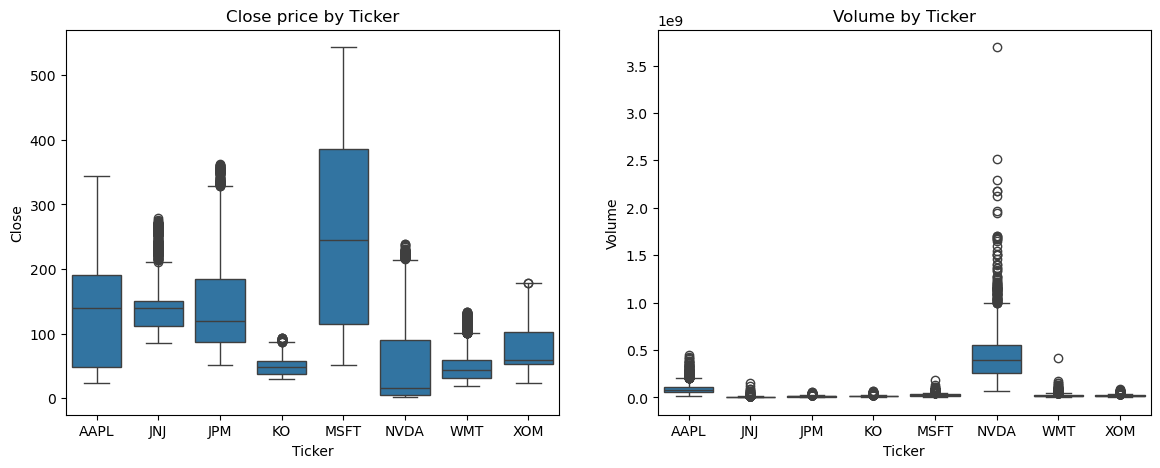

In [10]:
# Check the outliers
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.boxplot(data=df, x="Ticker", y="Close", ax=axes[0])
axes[0].set_title("Close price by Ticker")
sns.boxplot(data=df, x="Ticker", y="Volume", ax=axes[1])
axes[1].set_title("Volume by Ticker")
plt.show()

In [11]:
# Convert Date to datetime
if "Date" not in df.columns:
    df = df.reset_index()
df["Date"] = pd.to_datetime(df["Date"])

# Check for duplicates
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate (Date, Ticker):", df.duplicated(subset=["Date","Ticker"]).sum())
df = df.drop_duplicates(subset=["Date","Ticker"])

# Sort by Ticker and Date
df = df.sort_values(["Ticker","Date"]).reset_index(drop=True)
print(df.dtypes)
print(df["Date"].min(), "->", df["Date"].max())

Duplicate rows: 0
Duplicate (Date, Ticker): 0
Date      datetime64[ns]
Ticker            object
Open             float64
High             float64
Low              float64
Close            float64
Volume             int64
dtype: object
2016-10-24 00:00:00 -> 2026-10-21 00:00:00


In [12]:
gp = df.groupby("Ticker")

df["Return"]       = gp["Close"].pct_change()                      
df["Log_Return"]   = np.log(df["Close"] / gp["Close"].shift(1))
df["Volatility_20"] = gp["Return"].transform(lambda x: x.rolling(20).std())
df["MA_50"]        = gp["Close"].transform(lambda x: x.rolling(50).mean())
df["Price_Range"]  = (df["High"] - df["Low"]) / df["Close"]      
df["Log_Volume"]   = np.log(df["Volume"])

# Remove NaN values created by pct_change and rolling windows
before = len(df)
df_feat = df.dropna().reset_index(drop=True)
print(f"~Dropped {before - len(df_feat)} rows with NaN (first rows of rolling windows)~")
print(df_feat.head())

~Dropped 392 rows with NaN (first rows of rolling windows)~
        Date Ticker       Open       High        Low      Close     Volume  \
0 2017-01-04   AAPL  26.629255  26.780964  26.606270  26.668331   84472400   
1 2017-01-05   AAPL  26.645344  26.861412  26.620059  26.803947   88774400   
2 2017-01-06   AAPL  26.843023  27.160231  26.771767  27.102766  127007600   
3 2017-01-09   AAPL  27.111961  27.452154  27.109663  27.351015  134247600   
4 2017-01-10   AAPL  27.300446  27.440661  27.192413  27.378599   97848400   

     Return  Log_Return  Volatility_20      MA_50  Price_Range  Log_Volume  
0 -0.001119   -0.001120       0.006830  25.905239     0.006551   18.251935  
1  0.005085    0.005072       0.006762  25.903221     0.009004   18.301609  
2  0.011148    0.011087       0.006839  25.904434     0.014333   18.659757  
3  0.009160    0.009118       0.006806  25.922779     0.012522   18.715196  
4  0.001009    0.001008       0.006047  25.946753     0.009067   18.398930  


In [13]:
def max_drawdown(close):
    # Largest peak-to-trough decline over the period
    peak = close.cummax()
    return ((close - peak) / peak).min()

summary = df_feat.groupby("Ticker").agg(
    # annualised
    Annual_Return=("Return", lambda x: x.mean() * 252),                       
    Annual_Volatility=("Return", lambda x: x.std() * np.sqrt(252)), 
    # average
    Avg_Price_Range=("Price_Range", "mean"),
    Avg_Log_Volume=("Log_Volume", "mean"),
)
summary["Sharpe"] = summary["Annual_Return"] / summary["Annual_Volatility"]
summary["Max_Drawdown"] = df_feat.groupby("Ticker")["Close"].apply(max_drawdown)

print(summary.round(3))

# Standard scaling
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(summary)

        Annual_Return  Annual_Volatility  Avg_Price_Range  Avg_Log_Volume  \
Ticker                                                                      
AAPL            0.305              0.293            0.021          18.202   
JNJ             0.127              0.190            0.015          15.773   
JPM             0.202              0.275            0.019          16.253   
KO              0.130              0.185            0.014          16.428   
MSFT            0.270              0.279            0.020          17.057   
NVDA            0.580              0.493            0.035          19.737   
WMT             0.209              0.223            0.017          16.839   
XOM             0.153              0.286            0.021          16.613   

        Sharpe  Max_Drawdown  
Ticker                        
AAPL     1.038        -0.385  
JNJ      0.668        -0.274  
JPM      0.736        -0.436  
KO       0.699        -0.370  
MSFT     0.965        -0.371  
NVDA     1.1

   k  Inertia  Silhouette  Davies_Bouldin
0  2   15.967       0.555           0.237
1  3    8.257       0.274           0.681
2  4    4.075       0.312           0.544
3  5    2.443       0.233           0.467
4  6    1.012       0.180           0.276


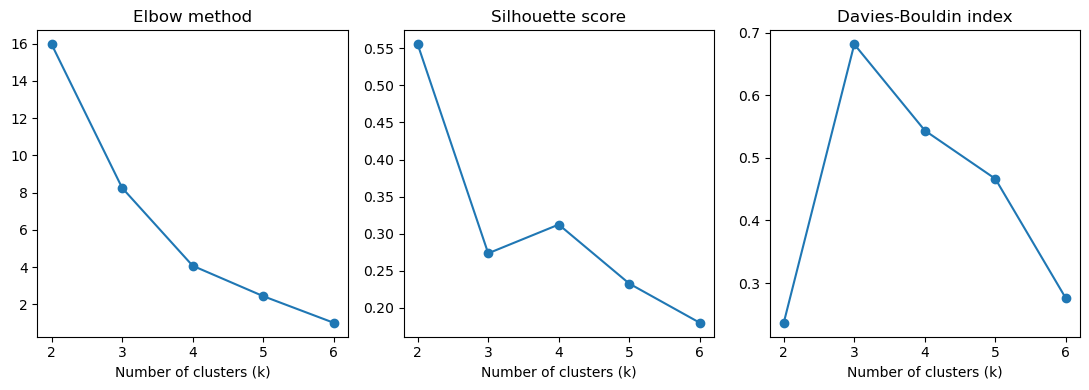

In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Try k = 2..6 
k_range = range(2, 7)
inertia, sil, dbi = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)                          #elbow_method                
    sil.append(silhouette_score(X, labels))              #silhouette_score
    dbi.append(davies_bouldin_score(X, labels))          #davies_bouldin_score

# Summary table of the two metrics
k_results = pd.DataFrame({"k": list(k_range), "Inertia": inertia, "Silhouette": sil, "Davies_Bouldin": dbi}).round(3)
print(k_results)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].plot(k_range, inertia, marker="o"); axes[0].set_title("Elbow method")
axes[1].plot(k_range, sil, marker="o");     axes[1].set_title("Silhouette score")
axes[2].plot(k_range, dbi, marker="o");      axes[2].set_title("Davies-Bouldin index")
for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

In [15]:
import skfuzzy as fuzz
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Final number of clusters chosen from the elbow, silhouette and Davies-Bouldin results
n_clusters = 4

# Algorithm 1: K-Means

# Applying KMeans to the dataset
kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

# Algorithm 2: Fuzzy C-Means

X_fcm = X.T
# Initilise the model object
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    X_fcm, c=n_clusters, m=2, error=0.005, maxiter=1000, init=None, seed=42
)
# Pick highest membership
fcm_labels = np.argmax(u, axis=0)

# Compare both algorithms with the same two internal validation metrics
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Fuzzy C-Means"],
    "Silhouette (higher = better)": [silhouette_score(X, kmeans_labels), silhouette_score(X, fcm_labels)],
    "Davies-Bouldin (lower = better)": [davies_bouldin_score(X, kmeans_labels), davies_bouldin_score(X, fcm_labels)],
}).round(3)
print(comparison)
print("\nFuzzy partition coefficient (FPC):", round(fpc, 3))
print("Adjusted Rand Index between the two groupings:", round(adjusted_rand_score(kmeans_labels, fcm_labels), 3))

       Algorithm  Silhouette (higher = better)  \
0        K-Means                         0.312   
1  Fuzzy C-Means                         0.246   

   Davies-Bouldin (lower = better)  
0                            0.544  
1                            0.532  

Fuzzy partition coefficient (FPC): 0.762
Adjusted Rand Index between the two groupings: 0.661


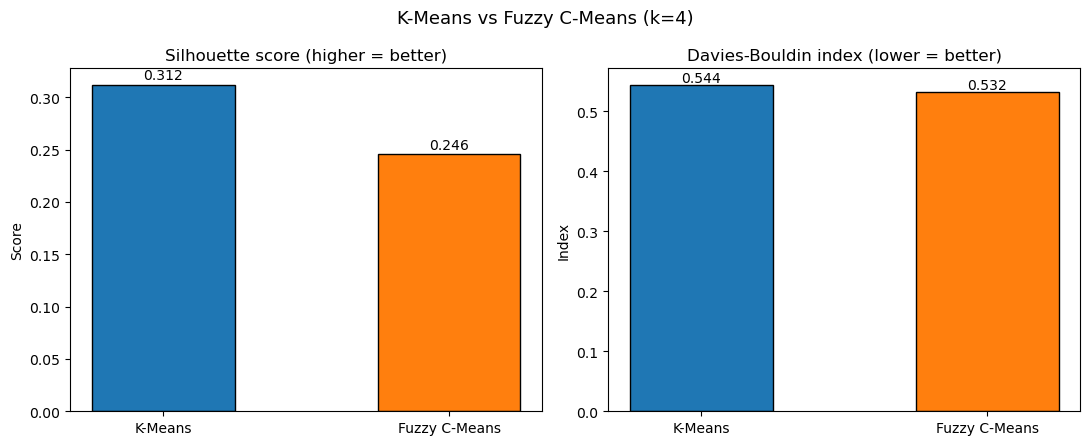

In [16]:
# Visualize the comparison
# Values taken from the comparison table
algorithms = comparison["Algorithm"].tolist()
sil_values = comparison["Silhouette (higher = better)"].tolist()
dbi_values = comparison["Davies-Bouldin (lower = better)"].tolist()

x = np.arange(len(algorithms))
colours = ["tab:blue", "tab:orange"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: Silhouette score (higher is better)
bars = axes[0].bar(x, sil_values, color=colours, edgecolor="black", width=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(algorithms)
axes[0].set_title("Silhouette score (higher = better)")
axes[0].set_ylabel("Score")
for bar, v in zip(bars, sil_values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center")

# Right: Davies-Bouldin index (lower is better)
bars = axes[1].bar(x, dbi_values, color=colours, edgecolor="black", width=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(algorithms)
axes[1].set_title("Davies-Bouldin index (lower = better)")
axes[1].set_ylabel("Index")
for bar, v in zip(bars, dbi_values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center")

plt.suptitle(f"K-Means vs Fuzzy C-Means (k={n_clusters})", fontsize=13)
plt.tight_layout()
plt.show()

In [17]:
# Companies in each cluster for both algorithms
result = summary.copy()
result["KMeans_Cluster"] = kmeans_labels
result["FCM_Cluster"] = fcm_labels
print(result[["KMeans_Cluster", "FCM_Cluster"]])

# Membership matrix: degree to which each company belongs to each cluster
membership = pd.DataFrame(u.T, index=summary.index,
                          columns=[f"Cluster_{i}" for i in range(n_clusters)]).round(2)
membership["Max_Membership"] = membership.max(axis=1)
print(membership)

# Companies whose highest membership is low sit between clusters 
ambiguous = membership[membership["Max_Membership"] < 0.6]
print("\nCompanies with ambiguous membership (< 0.6):", ambiguous.index.tolist())

# Business interpretation: average feature values per K-Means cluster
profile = result.drop(columns=["FCM_Cluster"]).groupby("KMeans_Cluster").mean().round(3)
print("\nK-Means cluster profile:")
print(profile)

        KMeans_Cluster  FCM_Cluster
Ticker                             
AAPL                 0            2
JNJ                  3            3
JPM                  1            3
KO                   3            3
MSFT                 0            2
NVDA                 2            1
WMT                  0            2
XOM                  1            0
        Cluster_0  Cluster_1  Cluster_2  Cluster_3  Max_Membership
Ticker                                                            
AAPL         0.05       0.03       0.86       0.06            0.86
JNJ          0.04       0.00       0.04       0.92            0.92
JPM          0.35       0.02       0.26       0.37            0.37
KO           0.04       0.00       0.03       0.93            0.93
MSFT         0.01       0.00       0.96       0.02            0.96
NVDA         0.00       1.00       0.00       0.00            1.00
WMT          0.08       0.02       0.51       0.39            0.51
XOM          0.99       0.00       0.

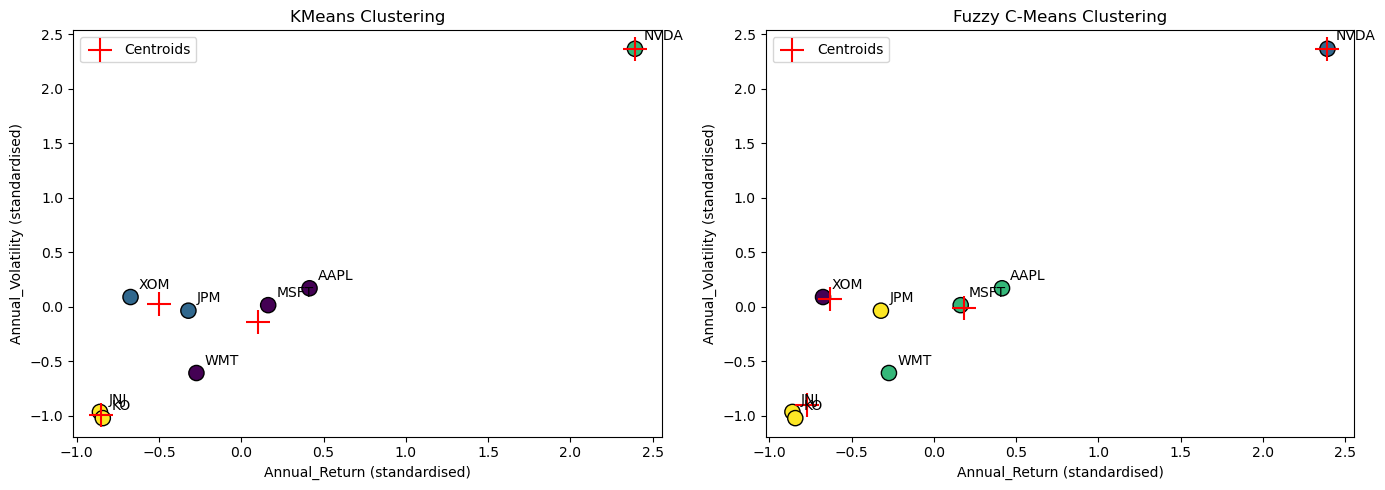

In [18]:
# Visualize
# Pick two features to plot
fx, fy = 0, 1   # 0 = Annual_Return, 1 = Annual_Volatility
names = summary.columns.tolist()

plt.figure(figsize=(14, 5))

# Plot K-Means results
plt.subplot(1, 2, 1)
plt.scatter(X[:, fx], X[:, fy], c=kmeans_labels, cmap="viridis", s=120, edgecolors="black")
plt.scatter(kmeans.cluster_centers_[:, fx], kmeans.cluster_centers_[:, fy],
            c="red", marker="+", s=300, label="Centroids")
for i, ticker in enumerate(summary.index):
    plt.annotate(ticker, (X[i, fx], X[i, fy]), xytext=(6, 6), textcoords="offset points")
plt.xlabel(names[fx] + " (standardised)")
plt.ylabel(names[fy] + " (standardised)")
plt.title("KMeans Clustering")
plt.legend()

# Plot Fuzzy C-Means results
plt.subplot(1, 2, 2)
plt.scatter(X[:, fx], X[:, fy], c=fcm_labels, cmap="viridis", s=120, edgecolors="black")
plt.scatter(cntr[:, fx], cntr[:, fy], c="red", marker="+", s=300, label="Centroids")
for i, ticker in enumerate(summary.index):
    plt.annotate(ticker, (X[i, fx], X[i, fy]), xytext=(6, 6), textcoords="offset points")
plt.xlabel(names[fx] + " (standardised)")
plt.ylabel(names[fy] + " (standardised)")
plt.title("Fuzzy C-Means Clustering")
plt.legend()

plt.tight_layout()
plt.show()

Total variance retained: 0.982


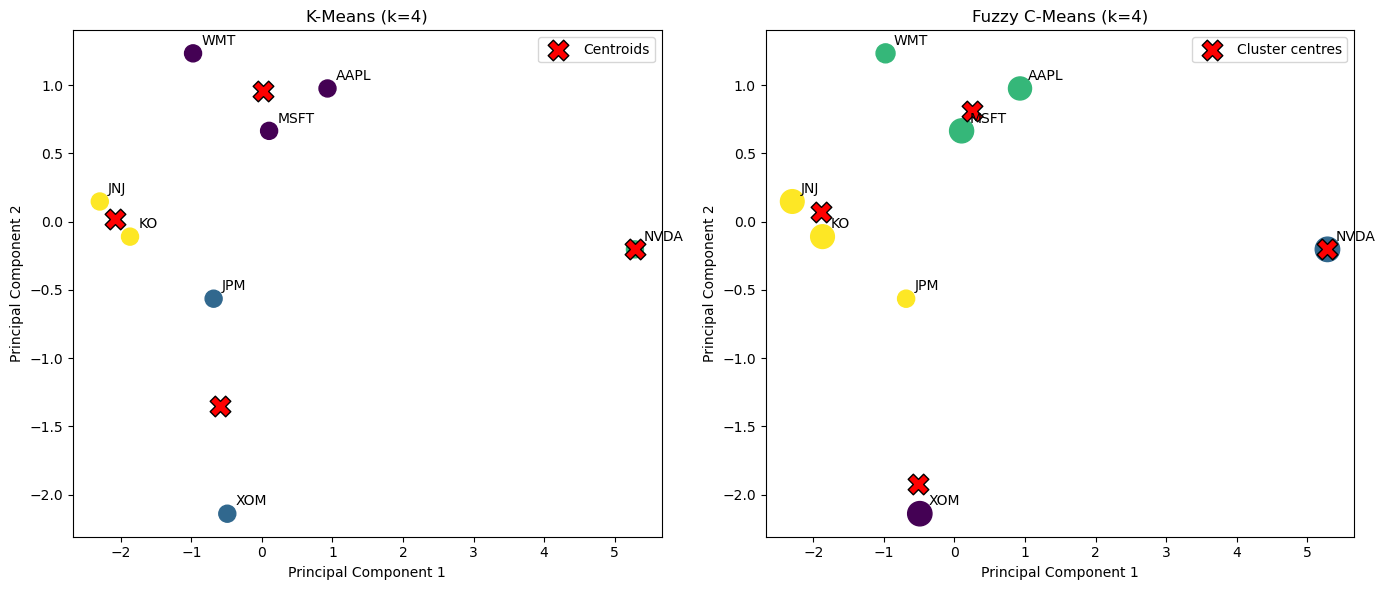

In [19]:
from sklearn.decomposition import PCA

# Reduce the 6 standardised features to 2 principal components for plotting
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print("Total variance retained:", round(pca.explained_variance_ratio_.sum(), 3))

# Project both sets of cluster centres into the same 2D space
kmeans_centers_pca = pca.transform(kmeans.cluster_centers_)
fcm_centers_pca = pca.transform(cntr)

plt.figure(figsize=(14, 6))

# Left: K-Means
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=150)
plt.scatter(kmeans_centers_pca[:, 0], kmeans_centers_pca[:, 1],
            c="red", marker="X", s=220, edgecolors="black", label="Centroids")
for i, ticker in enumerate(summary.index):
    plt.annotate(ticker, (X_pca[i, 0], X_pca[i, 1]), xytext=(6, 6), textcoords="offset points")
plt.title("K-Means (k=4)")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.legend(loc="best")

# Right: Fuzzy C-Means
plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=fcm_labels, cmap="viridis",
            s=60 + 250 * u.max(axis=0))
plt.scatter(fcm_centers_pca[:, 0], fcm_centers_pca[:, 1],
            c="red", marker="X", s=220, edgecolors="black", label="Cluster centres")
for i, ticker in enumerate(summary.index):
    plt.annotate(ticker, (X_pca[i, 0], X_pca[i, 1]), xytext=(6, 6), textcoords="offset points")
plt.title("Fuzzy C-Means (k=4)")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.legend(loc="best")

plt.tight_layout()
plt.show()

Date
2016-10-24    26.904865
2016-10-25    27.042078
2016-10-26    26.433771
2016-10-27    26.179934
2016-10-28    26.006134
Freq: B, Name: Close, dtype: float64
Observations: 2608


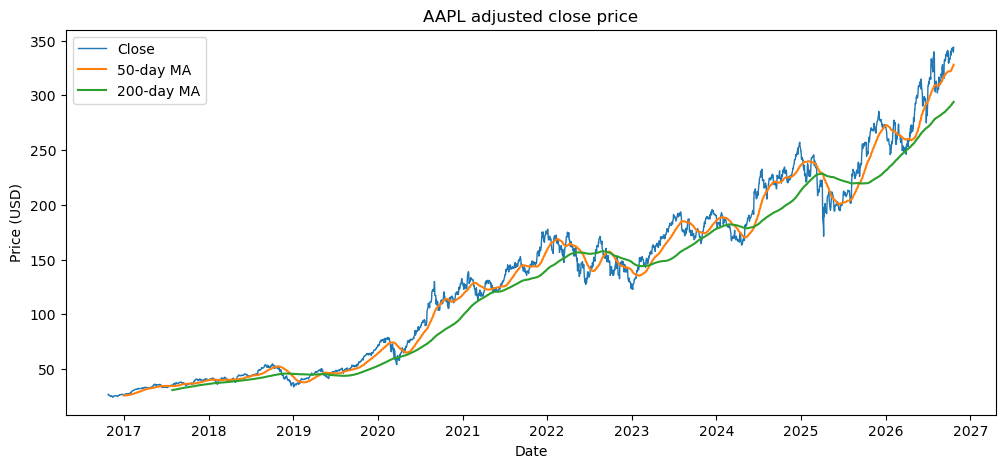

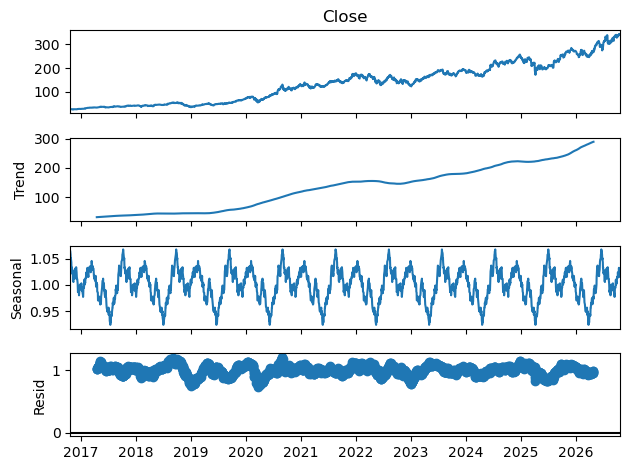

Anomalous return days:
Date
2019-01-03   -0.100
2020-03-02    0.093
2020-03-09   -0.079
2020-03-12   -0.099
2020-03-13    0.120
2020-03-16   -0.129
2020-03-24    0.100
2020-04-06    0.087
2020-07-31    0.105
2020-09-03   -0.080
2022-10-28    0.076
2022-11-10    0.089
2025-04-03   -0.092
2025-04-04   -0.073
2025-04-09    0.153
2026-07-31   -0.074
Name: Close, dtype: float64


In [20]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Select the AAPL closing price as a time series indexed by date
aapl = df[df["Ticker"] == "AAPL"].set_index("Date")["Close"].sort_index()

# Business-day data has small gaps (holidays); use a business-day frequency and forward-fill them
aapl = aapl.asfreq("B").ffill()
print(aapl.head())
print("Observations:", len(aapl))

# Plot the price with 50-day and 200-day moving averages to show the trend
plt.figure(figsize=(12, 5))
plt.plot(aapl, label="Close", linewidth=1)
plt.plot(aapl.rolling(50).mean(), label="50-day MA")
plt.plot(aapl.rolling(200).mean(), label="200-day MA")
plt.title("AAPL adjusted close price")
plt.xlabel("Date"); plt.ylabel("Price (USD)")
plt.legend()
plt.show()

# Decompose into trend, seasonal and residual parts (about 21 business days per month)
decomp = seasonal_decompose(aapl, model="multiplicative", period=252)
decomp.plot()
plt.tight_layout()
plt.show()

# Simple anomaly detection: daily returns more than 4 standard deviations from the mean
ret = aapl.pct_change().dropna()
anomalies = ret[(ret - ret.mean()).abs() > 4 * ret.std()]
print("Anomalous return days:")
print(anomalies.round(3))

Log price (d=0): ADF statistic = -1.208, p-value = 0.6702 -> NOT stationary
First difference (d=1): ADF statistic = -16.895, p-value = 0.0000 -> stationary


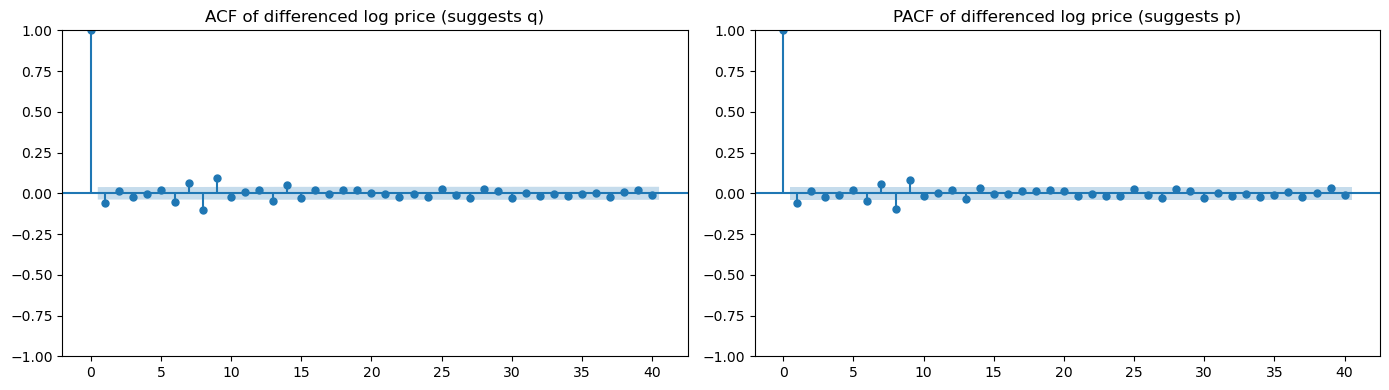

In [21]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def adf_report(series, name):
    # Dickey-Fuller test
    stat, p, *_ = adfuller(series.dropna())
    print(f"{name}: ADF statistic = {stat:.3f}, p-value = {p:.4f} -> "
          f"{'stationary' if p < 0.05 else 'NOT stationary'}")

# Use log prices so that variance is more stable
log_price = np.log(aapl)

adf_report(log_price, "Log price (d=0)")
adf_report(log_price.diff(), "First difference (d=1)")

# ACF and PACF of the differenced series suggest q and p
diff1 = log_price.diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(diff1, lags=40, ax=axes[0]);  axes[0].set_title("ACF of differenced log price (suggests q)")
plot_pacf(diff1, lags=40, ax=axes[1]); axes[1].set_title("PACF of differenced log price (suggests p)")
plt.tight_layout()
plt.show()

mean1 = 4.059, mean2 = 5.291
variance1 = 0.267, variance2 = 0.062


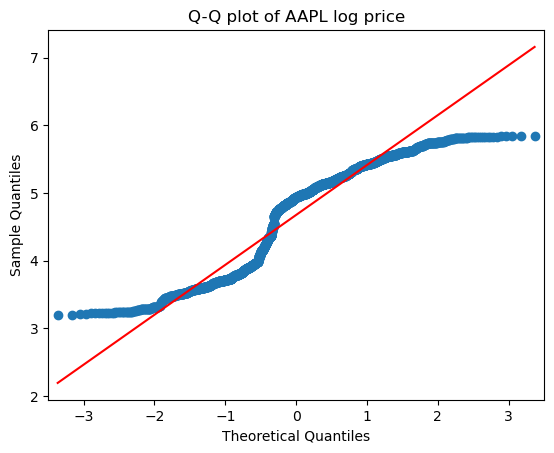

In [22]:
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

# Compare mean and variance of the first and second half of the log price
half = len(log_price) // 2
mean1, mean2 = log_price.iloc[:half].mean(), log_price.iloc[half:].mean()
var1, var2 = log_price.iloc[:half].var(), log_price.iloc[half:].var()
print(f"mean1 = {mean1:.3f}, mean2 = {mean2:.3f}")
print(f"variance1 = {var1:.3f}, variance2 = {var2:.3f}")

# Q-Q plot of the log price against the normal distribution
sm.qqplot(log_price, line="s")
plt.title("Q-Q plot of AAPL log price")
plt.show()

In [23]:
# d is fixed at 1 because the ADF test showed one difference makes the series stationary.
# AIC is only comparable between models with the same d, so only p and q are searched.
d_arima = 1
aic_rows = []
for p_ in range(0, 4):
    for q_ in range(0, 4):
        try:
            fit = ARIMA(log_price, order=(p_, d_arima, q_)).fit()
            aic_rows.append([p_, d_arima, q_, fit.aic, fit.bic])
        except Exception:
            pass   # skip combinations that fail to converge

aic_table = pd.DataFrame(aic_rows, columns=["p", "d", "q", "AIC", "BIC"]).sort_values("AIC")
print(aic_table.round(1).to_string(index=False))

# Find the minimum AIC value and the corresponding model
best = aic_table.iloc[0]
best_order = (int(best["p"]), int(best["d"]), int(best["q"]))
print(f"\nMinimum AIC value: {best['AIC']:.2f}")
print(f"Best model: ARIMA{best_order}")

C:\Users\Dell\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


 p  d  q      AIC      BIC
 1  1  0 -13544.7 -13533.0
 0  1  1 -13544.4 -13532.7
 1  1  1 -13543.5 -13525.9
 2  1  0 -13543.3 -13525.7
 0  1  2 -13543.1 -13525.5
 3  1  0 -13542.2 -13518.7
 0  1  3 -13542.2 -13518.7
 2  1  1 -13541.3 -13517.8
 1  1  2 -13541.0 -13517.5
 1  1  3 -13540.4 -13511.0
 3  1  1 -13540.2 -13510.9
 2  1  2 -13538.9 -13509.5
 0  1  0 -13538.4 -13532.5
 2  1  3 -13538.4 -13503.2
 3  1  2 -13537.9 -13502.7
 3  1  3 -13536.3 -13495.2

Minimum AIC value: -13544.69
Best model: ARIMA(1, 1, 0)


                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 2608
Model:                 ARIMA(1, 1, 0)   Log Likelihood                6774.347
Date:                Thu, 29 Oct 2026   AIC                         -13544.694
Time:                        20:26:07   BIC                         -13532.962
Sample:                    10-24-2016   HQIC                        -13540.443
                         - 10-21-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0564      0.011     -4.917      0.000      -0.079      -0.034
sigma2         0.0003   4.59e-06     70.502      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   0.02   Jarque-

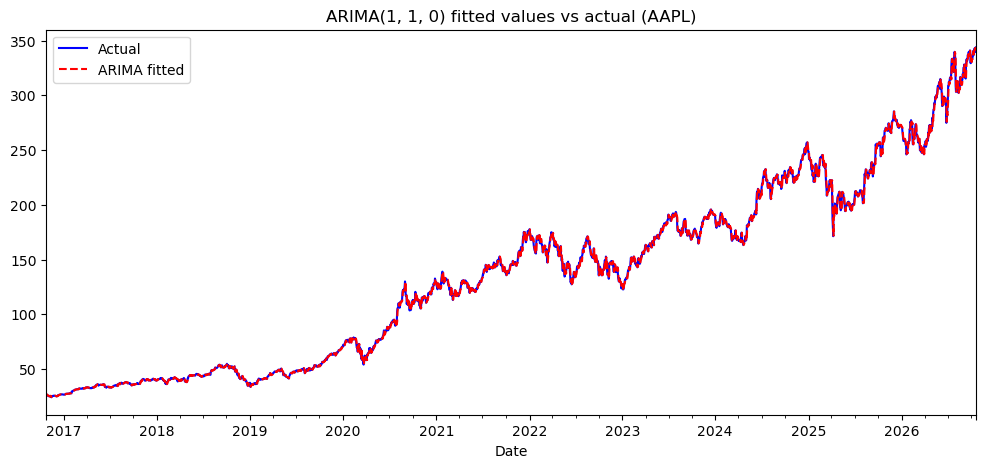

R2 (in-sample, price scale): 0.999


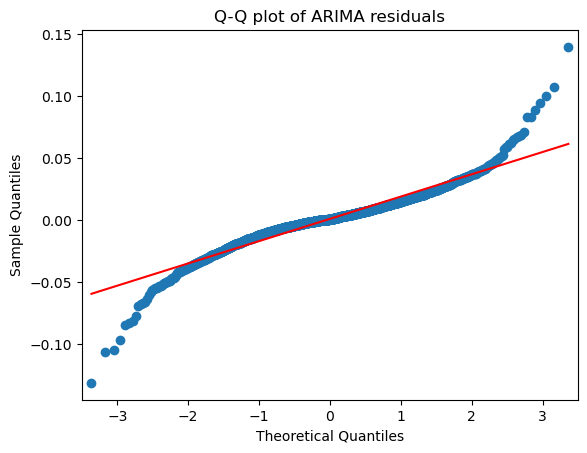

      lb_stat     lb_pvalue
10  60.083759  3.494408e-09
20  77.006443  1.257412e-08


In [24]:
from sklearn.metrics import r2_score
from statsmodels.stats.diagnostic import acorr_ljungbox

# Train the selected model 
arima_fit = ARIMA(log_price, order=best_order).fit()
print(arima_fit.summary())

# One-step-ahead fitted values converted back to price (first value is only initialisation)
fitted_price = np.exp(arima_fit.fittedvalues).iloc[1:]
actual_price = aapl.loc[fitted_price.index]

plt.figure(figsize=(12, 5))
actual_price.plot(color="b", label="Actual")
fitted_price.plot(color="r", linestyle="--", label="ARIMA fitted")
plt.title(f"ARIMA{best_order} fitted values vs actual (AAPL)")
plt.legend()
plt.show()

print("R2 (in-sample, price scale):", round(r2_score(actual_price, fitted_price), 4))

# Q-Q plot of the residuals and Ljung-Box test for leftover autocorrelation
residuals = arima_fit.resid.iloc[1:]
sm.qqplot(residuals, line="s")
plt.title("Q-Q plot of ARIMA residuals")
plt.show()
print(acorr_ljungbox(residuals, lags=[10, 20], return_df=True))

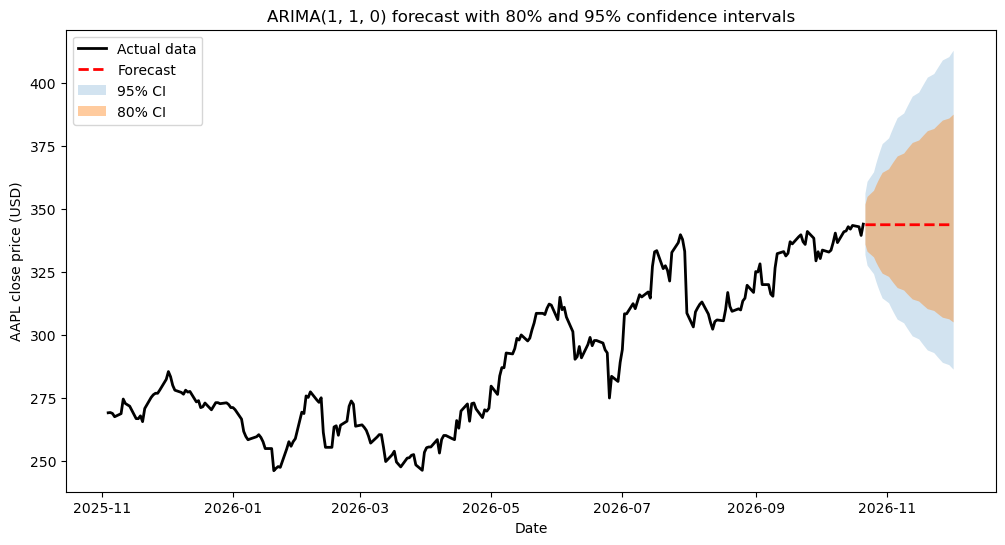

In [25]:
# Forecast the next 30 business days and convert back to price
steps = 30
fc = arima_fit.get_forecast(steps=steps)
pred_f = np.exp(fc.predicted_mean)
ci80 = np.exp(fc.conf_int(alpha=0.20))
ci95 = np.exp(fc.conf_int(alpha=0.05))

# Plot the last year of data followed by the forecast
history = aapl.iloc[-252:]
plt.figure(figsize=(12, 6))
plt.plot(history.index, history, color="black", linewidth=2, label="Actual data")
plt.plot(pred_f.index, pred_f, color="red", linestyle="--", linewidth=2, label="Forecast")
plt.fill_between(pred_f.index, ci95.iloc[:, 0], ci95.iloc[:, 1], alpha=0.2, label="95% CI")
plt.fill_between(pred_f.index, ci80.iloc[:, 0], ci80.iloc[:, 1], alpha=0.4, label="80% CI")
plt.xlabel("Date"); plt.ylabel("AAPL close price (USD)")
plt.title(f"ARIMA{best_order} forecast with 80% and 95% confidence intervals")
plt.legend()
plt.show()

# Reference
- Hyndman, R.J. and Athanasopoulos, G. (2021) ‘Stationarity and differencing’, in Forecasting: principles and practice. 3rd edn. Melbourne: OTexts. Available at: https://otexts.com/fpp3/stationarity.html (Accessed: 26 October 2026).
- Hyndman, R.J. and Athanasopoulos, G. (2021) ‘Non-seasonal ARIMA models’, in Forecasting: principles and practice. 3rd edn. Melbourne: OTexts. Available at: https://otexts.com/fpp3/non-seasonal-arima.html (Accessed: 27 October 2026).
- scikit-fuzzy developers (n.d.) Fuzzy c-means clustering. Available at: https://scikit-fuzzy.github.io/scikit-fuzzy/auto_examples/plot_cmeans.html (Accessed: 29 October 2026).
- Iqbal, M. (2026) Tutorial 1 – Clustering [Jupyter notebook]. Machine Learning for Business. CCT College Dublin. Available at: https://moodle.cct.ie/course/view.php?id=3559 (Accessed: 14 October 2026).
- Iqbal, M. (2026) Tutorial 4 – Fuzzy CMeans Clustering [Jupyter notebook]. Machine Learning for Business. CCT College Dublin. Available at: https://moodle.cct.ie/course/view.php?id=3559 (Accessed: 18 October 2026).

- Iqbal, M. (2026) Tutorial 6 (a) – ARIMA Model [Jupyter notebook]. Machine Learning for Business. CCT College Dublin. Available at: https://moodle.cct.ie/course/view.php?id=3559 (Accessed: 27 October 2026).

- Iqbal, M. (2026) Tutorial 6 (b) – SARIMA Electricity-Generation-Forecast [Jupyter notebook]. Machine Learning for Business. CCT College Dublin. Available at: https://moodle.cct.ie/course/view.php?id=3559 (Accessed: 27 October 2026).
- Yahoo Finance (2026) Historical data for AAPL, MSFT, NVDA, JPM, XOM, JNJ, KO and WMT. Available at: https://finance.yahoo.com/ (Accessed: 12 October 2026).